# BÀI 4 – BÀI TẬP MỞ RỘNG: MLP CHO FASHION-MNIST

Notebook chạy 6 bài tập ở mục **"22. Bài tập mở rộng cho sinh viên"** của Bài 4.

| Bài | Nội dung | Thí nghiệm |
|---|---|---|
| 1 | Thay đổi kiến trúc | 1 / 2 / 3 hidden layers |
| 2 | Thử learning rate | `1e-2`, `1e-3`, `1e-4` |
| 3 | Thử batch size | 32, 128, 512 (so với 64 của baseline) |
| 4 | Thêm Dropout | `Dropout(0.3)` giữa các Dense layer |
| 5 | Thêm L2 regularization | `l2(1e-4)`, `l2(1e-3)` |
| 6 | Phân tích lỗi | 20 mẫu sai có confidence cao nhất |

Mỗi bài in kết quả dạng `======== tiêu đề ========` + bảng, một biểu đồ và phần nhận xét.

### Cách chạy
1. Mở trên **Google Colab** → `Runtime` → `Change runtime type` → **GPU (T4)**.
2. `Runtime` → **`Run all`** (khoảng 15–25 phút với GPU, 40–60 phút với CPU).

> `QUICK_MODE = True` để chạy thử nhanh 3 epoch/mô hình – chỉ dùng kiểm tra code.

**Quy ước:** giữ nguyên quy trình bài mẫu (chia 50,000 / 10,000 / 10,000, chuẩn hóa `/255`, Adam, `SparseCategoricalCrossentropy`, `EarlyStopping(patience=3, restore_best_weights=True)`, `ModelCheckpoint`). Baseline là mô hình của bài mẫu `784 → 256 → 128 → 10`, `lr = 1e-3`, `batch = 64`; mỗi bài chỉ đổi **một** yếu tố so với baseline; cùng `SEED = 42`; chọn mô hình theo **validation**, **test** chỉ để đánh giá cuối.

## 0. Cấu hình, thư viện, random seed

In [1]:
import os, time, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
import tensorflow as tf
from sklearn.metrics import confusion_matrix

# ----- Cấu hình thí nghiệm -----
SEED        = 42
QUICK_MODE  = False
MAX_EPOCHS  = 3 if QUICK_MODE else 40   # giống bài mẫu
PATIENCE    = 3
VAL_SIZE    = 10_000
BASE_HIDDEN = (256, 128)
BASE_LR     = 1e-3
BASE_BATCH  = 64

FIG_DIR, CKPT_DIR = "bai4_figures", "bai4_checkpoints"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


set_seed()

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # màu cho từng cấu hình
INK = "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150,
    "font.size": 9.5, "axes.titlesize": 10, "axes.labelsize": 9.5, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "xtick.color": INK, "ytick.color": INK,
    "grid.color": "#d9d8d4", "grid.linewidth": 0.8,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "không có (chạy CPU)")

TensorFlow version: 2.21.0
GPU: không có (chạy CPU)


## 1. Dữ liệu

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

X_val, y_val     = X_train_full[-VAL_SIZE:], y_train_full[-VAL_SIZE:]
X_train, y_train = X_train_full[:-VAL_SIZE], y_train_full[:-VAL_SIZE]
X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print("Training  :", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Training  : (50000, 28, 28) | Validation: (10000, 28, 28) | Test: (10000, 28, 28)


## 2. Hàm dùng chung

- `run_experiment(...)`: build → compile → fit (EarlyStopping + ModelCheckpoint) → nạp lại mô hình tốt nhất → đo train/val/test. Kết quả lưu trong `RESULTS`; chạy lại cell không train lại (dùng `force=True` nếu muốn).
- `train_acc` được **đo lại trên tập train ở chế độ inference** (Dropout tắt); `gap = train_acc − val_acc`.
- `val_loss`, `test_loss` trong bảng là **cross-entropy thuần** tính từ dự đoán (không gồm phần phạt L2).
- Biểu đồ của mỗi bài được lưu thêm vào thư mục `bai4_figures/`.

In [3]:
AUTOTUNE = tf.data.AUTOTUNE


def make_train_ds(batch_size):
    return (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(buffer_size=len(X_train), seed=SEED)
            .batch(batch_size)
            .prefetch(AUTOTUNE))


def make_eval_ds(X, y, batch_size=1024):
    return tf.data.Dataset.from_tensor_slices((X, y)).batch(batch_size).prefetch(AUTOTUNE)


def build_model(hidden_units=BASE_HIDDEN, dropout=0.0, l2=0.0, name="mlp"):
    reg = tf.keras.regularizers.l2(l2) if l2 > 0 else None
    layers = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten(name="flatten")]
    for i, units in enumerate(hidden_units, start=1):
        layers.append(tf.keras.layers.Dense(units, activation="relu", kernel_regularizer=reg, name=f"hidden_{i}"))
        if dropout > 0:
            layers.append(tf.keras.layers.Dropout(dropout, name=f"dropout_{i}"))   # Dropout giữa các Dense layer
    layers.append(tf.keras.layers.Dense(10, activation="softmax", name="output"))
    return tf.keras.Sequential(layers, name=name)


class EpochTimer(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self._t0)


def predict_stats(model, X, y):
    p = model.predict(X, batch_size=1024, verbose=0)
    ce = float(-np.mean(np.log(np.clip(p[np.arange(len(y)), y], 1e-7, 1.0))))
    acc = float(np.mean(np.argmax(p, axis=1) == y))
    return p, ce, acc


RESULTS = {}


def run_experiment(exp_id, label, hidden_units=BASE_HIDDEN, lr=BASE_LR, batch_size=BASE_BATCH,
                   dropout=0.0, l2=0.0, force=False):
    if exp_id in RESULTS and not force:
        print(f"[{exp_id}] đã có kết quả – dùng lại.")
        return RESULTS[exp_id]

    tf.keras.backend.clear_session()
    set_seed(SEED)
    train_ds = make_train_ds(batch_size)
    val_ds = make_eval_ds(X_val, y_val)

    model = build_model(hidden_units, dropout, l2, name=exp_id)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                  metrics=["accuracy"])

    ckpt_path = os.path.join(CKPT_DIR, f"{exp_id}.keras")
    timer = EpochTimer()
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(filepath=ckpt_path, monitor="val_loss", save_best_only=True),
        timer,
    ]
    print(f"\n=== [{exp_id}] {label} | hidden={tuple(hidden_units)}, lr={lr:g}, batch={batch_size}, "
          f"dropout={dropout}, l2={l2:g} ===")
    t0 = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2)
    train_time = time.perf_counter() - t0

    hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    best_idx = int(np.argmin(hist["val_loss"]))

    best_model = tf.keras.models.load_model(ckpt_path, compile=False)   # trọng số epoch có val_loss nhỏ nhất
    _, train_ce, train_acc = predict_stats(best_model, X_train, y_train)
    _, val_ce, val_acc = predict_stats(best_model, X_val, y_val)
    y_prob, test_ce, test_acc = predict_stats(best_model, X_test, y_test)
    kernel_sq = float(sum(np.sum(np.square(layer.get_weights()[0]))
                          for layer in best_model.layers if isinstance(layer, tf.keras.layers.Dense)))

    res = dict(exp_id=exp_id, label=label, hidden_units=tuple(hidden_units), lr=lr, batch_size=batch_size,
               dropout=dropout, l2=l2, params=int(model.count_params()),
               steps_per_epoch=int(np.ceil(len(X_train) / batch_size)),
               epochs_run=len(hist["loss"]), best_epoch=best_idx + 1,
               train_time=train_time, sec_per_epoch=float(np.median(timer.times)),
               best_val_loss_keras=hist["val_loss"][best_idx],
               train_acc=train_acc, train_loss=train_ce, val_acc=val_acc, val_loss=val_ce,
               test_acc=test_acc, test_loss=test_ce, gap=train_acc - val_acc, kernel_sq=kernel_sq,
               history=hist, y_prob=y_prob.astype("float32"))
    RESULTS[exp_id] = res
    print(f"-> epoch tốt nhất {res['best_epoch']}/{res['epochs_run']} | train acc {train_acc:.4f} | "
          f"val acc {val_acc:.4f} | test acc {test_acc:.4f} | {train_time:.1f} s")
    return res

In [4]:
# ---------- Bảng kết quả ----------
f4 = lambda x: f"{x:.4f}"


def n_ups(r):
    """Số lần val_loss tăng so với epoch trước (độ dao động của learning curve)."""
    return int(np.sum(np.diff(r["history"]["val_loss"]) > 0))


COLS = {
    "params":         lambda r: f"{r['params']:,}",
    "time_s":         lambda r: f"{r['train_time']:.1f}",
    "s/epoch":        lambda r: f"{r['sec_per_epoch']:.2f}",
    "steps/epoch":    lambda r: f"{r['steps_per_epoch']:,}",
    "epochs":         lambda r: str(r["epochs_run"]),
    "best_epoch":     lambda r: str(r["best_epoch"]),
    "train_acc":      lambda r: f4(r["train_acc"]),
    "val_acc":        lambda r: f4(r["val_acc"]),
    "test_acc":       lambda r: f4(r["test_acc"]),
    "gap":            lambda r: f4(r["gap"]),
    "val_loss":       lambda r: f4(r["val_loss"]),
    "test_loss":      lambda r: f4(r["test_loss"]),
    "loss_epoch1":    lambda r: f4(r["history"]["loss"][0]),
    "val_loss_tăng":  lambda r: f"{n_ups(r)}/{r['epochs_run'] - 1}",
    "train_acc_fit":  lambda r: f4(r["history"]["accuracy"][r["best_epoch"] - 1]),
    "sum_w2":         lambda r: f"{r['kernel_sq']:.1f}",
}


def exp_table(exp_ids, labels, cols):
    return pd.DataFrame([{c: COLS[c](RESULTS[e]) for c in cols} for e in exp_ids],
                        index=[labels[e] for e in exp_ids])


# ---------- In kết quả ----------
def show_table(title, df):
    print(f"\n======== {title} ========")
    print(df.to_string())


def show_comments(heading, lines):
    print(f"\n{heading}")
    for line in lines:
        print("- " + line)


# ---------- Biểu đồ: 1 hình / bài ----------
def plot_compare(exp_ids, labels, title, fname, show_train=True, bar=None):
    """Trái: loss, giữa: accuracy (nét liền = train, nét đứt = validation, chấm = epoch tốt nhất).
    bar = (tiêu đề, hàm lấy giá trị, nhãn trục x) → thêm cột biểu đồ cột bên phải."""
    single = len(exp_ids) == 1
    ncols = 3 if bar else 2
    fig, axes = plt.subplots(1, ncols, figsize=(10.5 if bar else 9.5, 3.7))
    for k, eid in enumerate(exp_ids):
        r = RESULTS[eid]
        h, b = r["history"], r["best_epoch"]
        ep = np.arange(1, len(h["loss"]) + 1)
        c_tr = SERIES[0] if single else SERIES[k]
        c_va = SERIES[1] if single else SERIES[k]
        for ax, key in zip(axes[:2], ("loss", "accuracy")):
            if show_train:
                ax.plot(ep, h[key], color=c_tr, lw=1.8)
            ax.plot(ep, h["val_" + key], color=c_va, lw=1.8, ls="--")
            ax.scatter([b], [h["val_" + key][b - 1]], s=42, color=c_va, edgecolors="white", linewidths=1.2, zorder=3)
    for ax, name in zip(axes[:2], ("Loss", "Accuracy")):
        ax.set_title(name)
        ax.set_xlabel("Epoch")
        ax.grid(True)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    if bar:
        name, fn, ticks = bar
        vals = [fn(RESULTS[e]) for e in exp_ids]
        ax = axes[2]
        ax.bar(range(len(vals)), vals, color=SERIES[:len(vals)], width=0.6)
        for x, v in enumerate(vals):
            ax.text(x, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5, color="#0b0b0b")
        ax.set_xticks(range(len(vals)))
        ax.set_xticklabels(ticks)
        ax.set_title(name)
        ax.grid(axis="y")
    if single:
        handles = [Line2D([0], [0], color=SERIES[0], lw=2, label="train"),
                   Line2D([0], [0], color=SERIES[1], lw=2, ls="--", label="validation")]
    else:
        handles = [Line2D([0], [0], color=SERIES[k], lw=2.5, label=labels[e]) for k, e in enumerate(exp_ids)]
        if show_train:
            handles.append(Line2D([0], [0], color=INK, lw=1.8, label="train"))
        handles.append(Line2D([0], [0], color=INK, lw=1.8, ls="--", label="validation"))
    handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor=INK, markersize=7, label="epoch tốt nhất"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 4), frameon=False)
    fig.suptitle(title, fontsize=11, fontweight="bold")
    nrows_leg = int(np.ceil(len(handles) / 4))
    fig.tight_layout(rect=(0, 0.07 * nrows_leg + 0.02, 1, 1))
    path = os.path.join(FIG_DIR, fname)
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return path

## Bài 1. Thay đổi kiến trúc: 1 / 2 / 3 hidden layers
So sánh số parameter, thời gian train, validation accuracy, test accuracy. Mô hình 2 hidden layers chính là baseline của bài mẫu và được dùng làm mốc cho các bài sau.

In [5]:
B1_IDS = ["b1_1h", "baseline", "b1_3h"]
B1_LABELS = {"b1_1h": "1 hidden (256)", "baseline": "2 hidden (256-128)", "b1_3h": "3 hidden (256-128-64)"}
run_experiment("baseline", B1_LABELS["baseline"])            # baseline của bài mẫu, dùng lại cho Bài 2-6
run_experiment("b1_1h", B1_LABELS["b1_1h"], hidden_units=(256,))
run_experiment("b1_3h", B1_LABELS["b1_3h"], hidden_units=(256, 128, 64))



=== [baseline] 2 hidden (256-128) | hidden=(256, 128), lr=0.001, batch=64, dropout=0.0, l2=0 ===
Epoch 1/40


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 - 2s - 3ms/step - accuracy: 0.8209 - loss: 0.5033 - val_accuracy: 0.8560 - val_loss: 0.4032
Epoch 2/40
782/782 - 2s - 2ms/step - accuracy: 0.8655 - loss: 0.3687 - val_accuracy: 0.8612 - val_loss: 0.3719
Epoch 3/40
782/782 - 2s - 2ms/step - accuracy: 0.8788 - loss: 0.3296 - val_accuracy: 0.8606 - val_loss: 0.3892
Epoch 4/40
782/782 - 3s - 4ms/step - accuracy: 0.8872 - loss: 0.3045 - val_accuracy: 0.8774 - val_loss: 0.3482
Epoch 5/40
782/782 - 3s - 4ms/step - accuracy: 0.8929 - loss: 0.2865 - val_accuracy: 0.8798 - val_loss: 0.3296
Epoch 6/40
782/782 - 2s - 3ms/step - accuracy: 0.8988 - loss: 0.2707 - val_accuracy: 0.8819 - val_loss: 0.3180
Epoch 7/40
782/782 - 2s - 3ms/step - accuracy: 0.9023 - loss: 0.2611 - val_accuracy: 0.8821 - val_loss: 0.3283
Epoch 8/40
782/782 - 2s - 3ms/step - accuracy: 0.9076 - loss: 0.2472 - val_accuracy: 0.8845 - val_loss: 0.3284
Epoch 9/40
782/782 - 2s - 3ms/step - accuracy: 0.9098 - loss: 0.2400 - val_accuracy: 0.8898 - val_loss: 0.3065
Epoch 10/40


{'exp_id': 'b1_3h',
 'label': '3 hidden (256-128-64)',
 'hidden_units': (256, 128, 64),
 'lr': 0.001,
 'batch_size': 64,
 'dropout': 0.0,
 'l2': 0.0,
 'params': 242762,
 'steps_per_epoch': 782,
 'epochs_run': 12,
 'best_epoch': 9,
 'train_time': 21.619662199984305,
 'sec_per_epoch': 1.5793945000041276,
 'best_val_loss_keras': 0.3086903691291809,
 'train_acc': 0.92024,
 'train_loss': 0.21440257132053375,
 'val_acc': 0.8896,
 'val_loss': 0.3086903691291809,
 'test_acc': 0.8816,
 'test_loss': 0.33436572551727295,
 'gap': 0.03064,
 'kernel_sq': 2352.8212890625,
 'history': {'accuracy': [0.8171399831771851,
   0.8642799854278564,
   0.8773599863052368,
   0.8849400281906128,
   0.893060028553009,
   0.8979600071907043,
   0.901639997959137,
   0.9049400091171265,
   0.9076399803161621,
   0.9125400185585022,
   0.9147800207138062,
   0.9175400137901306],
  'loss': [0.5142379999160767,
   0.37151211500167847,
   0.33381327986717224,
   0.31152045726776123,
   0.29032519459724426,
   0.272913


======== Bài 1: So sánh số hidden layer ========
                        params time_s s/epoch epochs best_epoch train_acc val_acc test_acc     gap
1 hidden (256)         203,530   34.1    3.07     13         10    0.9199  0.8866   0.8830  0.0333
2 hidden (256-128)     235,146   29.7    2.38     12          9    0.9225  0.8898   0.8844  0.0327
3 hidden (256-128-64)  242,762   21.6    1.58     12          9    0.9202  0.8896   0.8816  0.0306


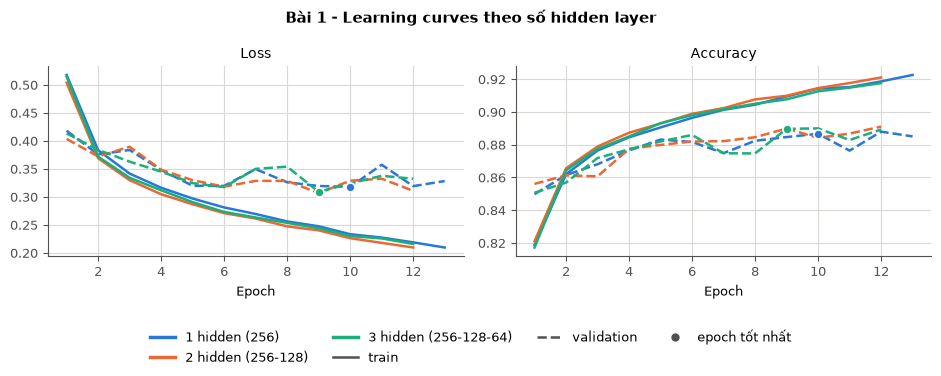


Nhận xét:
- Số tham số: 203,530 -> 235,146 -> 242,762. Thêm layer chỉ tăng ít tham số vì lớp Dense đầu tiên (784 -> 256) đã chiếm 200,960 tham số (~99% mô hình 1 hidden layer).
- Thời gian/epoch: 3.07 / 2.38 / 1.58 s -> không theo quy luật rõ ràng (chênh lệch nhỏ do overhead của máy). Tổng thời gian còn phụ thuộc số epoch trước khi EarlyStopping dừng (13 / 12 / 12 epoch).
- Val acc cao nhất: 2 hidden (256-128) (0.8898); chênh lệch giữa 3 kiến trúc chỉ 0.0032 -> tăng độ sâu gần như không cải thiện; giới hạn chính là Flatten làm mất cấu trúc không gian của ảnh, không phải số layer.
- Test acc: 0.8830 / 0.8844 / 0.8816 -> thứ hạng giống validation.
- Gap train - val: 0.0333 / 0.0327 / 0.0306 -> gap không tăng theo độ sâu vì EarlyStopping dừng trước khi overfit nhiều.
- Kết luận: theo validation chọn 2 hidden (256-128).


In [6]:
show_table("Bài 1: So sánh số hidden layer", exp_table(
    B1_IDS, B1_LABELS, ["params", "time_s", "s/epoch", "epochs", "best_epoch", "train_acc", "val_acc", "test_acc", "gap"]))
plot_compare(B1_IDS, B1_LABELS, "Bài 1 - Learning curves theo số hidden layer", "b1.png")


def comment_b1():
    r1, r2, r3 = (RESULTS[e] for e in B1_IDS)
    first = 784 * 256 + 256
    L = [f"Số tham số: {r1['params']:,} -> {r2['params']:,} -> {r3['params']:,}. Thêm layer chỉ tăng ít tham số vì lớp "
         f"Dense đầu tiên (784 -> 256) đã chiếm {first:,} tham số (~{first / r1['params'] * 100:.0f}% mô hình 1 hidden layer)."]
    spe = [r["sec_per_epoch"] for r in (r1, r2, r3)]
    if (max(spe) - min(spe)) / min(spe) < 0.10:
        s = "gần như không đổi (MLP nhỏ, thời gian chủ yếu là đọc dữ liệu và overhead)"
    elif spe[0] < spe[1] < spe[2]:
        s = "tăng dần theo độ sâu vì mỗi batch phải nhân thêm ma trận"
    else:
        s = "không theo quy luật rõ ràng (chênh lệch nhỏ do overhead của máy)"
    L.append(f"Thời gian/epoch: {spe[0]:.2f} / {spe[1]:.2f} / {spe[2]:.2f} s -> {s}. Tổng thời gian còn phụ thuộc số "
             f"epoch trước khi EarlyStopping dừng ({r1['epochs_run']} / {r2['epochs_run']} / {r3['epochs_run']} epoch).")
    best = max(B1_IDS, key=lambda e: RESULTS[e]["val_acc"])
    worst = min(B1_IDS, key=lambda e: RESULTS[e]["val_acc"])
    spread = RESULTS[best]["val_acc"] - RESULTS[worst]["val_acc"]
    t = (f"Val acc cao nhất: {B1_LABELS[best]} ({RESULTS[best]['val_acc']:.4f}); chênh lệch giữa 3 kiến trúc chỉ "
         f"{spread:.4f}")
    t += (" -> tăng độ sâu gần như không cải thiện; giới hạn chính là Flatten làm mất cấu trúc không gian của ảnh, "
          "không phải số layer." if spread < 0.005 else ".")
    L.append(t)
    test_best = max(B1_IDS, key=lambda e: RESULTS[e]["test_acc"])
    L.append(f"Test acc: {r1['test_acc']:.4f} / {r2['test_acc']:.4f} / {r3['test_acc']:.4f}"
             + (" -> thứ hạng giống validation." if test_best == best else
                " -> thứ hạng khác validation một chút; chênh lệch nhỏ nên vẫn chọn mô hình theo validation."))
    L.append(f"Gap train - val: {r1['gap']:.4f} / {r2['gap']:.4f} / {r3['gap']:.4f}"
             + (" -> mô hình sâu hơn có gap lớn hơn, dễ overfit hơn." if r3["gap"] > r1["gap"] else
                " -> gap không tăng theo độ sâu vì EarlyStopping dừng trước khi overfit nhiều."))
    L.append(f"Kết luận: theo validation chọn {B1_LABELS[best]}.")
    return L


show_comments("Nhận xét:", comment_b1())

## Bài 2. Thử learning rate: `1e-2`, `1e-3`, `1e-4`

In [7]:
B2_IDS = ["b2_lr_1e_2", "baseline", "b2_lr_1e_4"]
B2_LABELS = {"b2_lr_1e_2": "lr = 1e-2", "baseline": "lr = 1e-3", "b2_lr_1e_4": "lr = 1e-4"}
run_experiment("b2_lr_1e_2", B2_LABELS["b2_lr_1e_2"], lr=1e-2)
run_experiment("b2_lr_1e_4", B2_LABELS["b2_lr_1e_4"], lr=1e-4)


=== [b2_lr_1e_2] lr = 1e-2 | hidden=(256, 128), lr=0.01, batch=64, dropout=0.0, l2=0 ===
Epoch 1/40


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 - 2s - 3ms/step - accuracy: 0.8091 - loss: 0.5323 - val_accuracy: 0.8399 - val_loss: 0.4645
Epoch 2/40
782/782 - 2s - 2ms/step - accuracy: 0.8477 - loss: 0.4212 - val_accuracy: 0.8295 - val_loss: 0.4599
Epoch 3/40
782/782 - 3s - 3ms/step - accuracy: 0.8584 - loss: 0.3927 - val_accuracy: 0.8492 - val_loss: 0.4191
Epoch 4/40
782/782 - 3s - 4ms/step - accuracy: 0.8639 - loss: 0.3766 - val_accuracy: 0.8514 - val_loss: 0.4190
Epoch 5/40
782/782 - 3s - 4ms/step - accuracy: 0.8690 - loss: 0.3649 - val_accuracy: 0.8597 - val_loss: 0.3877
Epoch 6/40
782/782 - 3s - 4ms/step - accuracy: 0.8711 - loss: 0.3543 - val_accuracy: 0.8681 - val_loss: 0.3892
Epoch 7/40
782/782 - 3s - 4ms/step - accuracy: 0.8735 - loss: 0.3561 - val_accuracy: 0.8551 - val_loss: 0.4139
Epoch 8/40
782/782 - 3s - 4ms/step - accuracy: 0.8750 - loss: 0.3424 - val_accuracy: 0.8667 - val_loss: 0.3990
-> epoch tốt nhất 5/8 | train acc 0.8799 | val acc 0.8597 | test acc 0.8559 | 21.6 s

=== [b2_lr_1e_4] lr = 1e-4 | hidden=(

{'exp_id': 'b2_lr_1e_4',
 'label': 'lr = 1e-4',
 'hidden_units': (256, 128),
 'lr': 0.0001,
 'batch_size': 64,
 'dropout': 0.0,
 'l2': 0.0,
 'params': 235146,
 'steps_per_epoch': 782,
 'epochs_run': 11,
 'best_epoch': 8,
 'train_time': 35.298133200005395,
 'sec_per_epoch': 3.134515799989458,
 'best_val_loss_keras': 0.34364867210388184,
 'train_acc': 0.89252,
 'train_loss': 0.3020235300064087,
 'val_acc': 0.8761,
 'val_loss': 0.34364867210388184,
 'test_acc': 0.8722,
 'test_loss': 0.3659132719039917,
 'gap': 0.01641999999999999,
 'kernel_sq': 693.5032348632812,
 'history': {'accuracy': [0.7732999920845032,
   0.8453999757766724,
   0.8599799871444702,
   0.8678799867630005,
   0.8743600249290466,
   0.8794599771499634,
   0.8828200101852417,
   0.8870199918746948,
   0.8902400135993958,
   0.8924400210380554,
   0.8939999938011169],
  'loss': [0.7110791206359863,
   0.45042386651039124,
   0.40276098251342773,
   0.37697362899780273,
   0.35823529958724976,
   0.34233179688453674,
   0.


======== Bài 2: So sánh learning rate ========
          loss_epoch1 epochs best_epoch val_loss_tăng train_acc val_acc test_acc val_loss
lr = 1e-2      0.5323      8          5           2/7    0.8799  0.8597   0.8559   0.3877
lr = 1e-3      0.5033     12          9          5/11    0.9225  0.8898   0.8844   0.3065
lr = 1e-4      0.7111     11          8          2/10    0.8925  0.8761   0.8722   0.3436


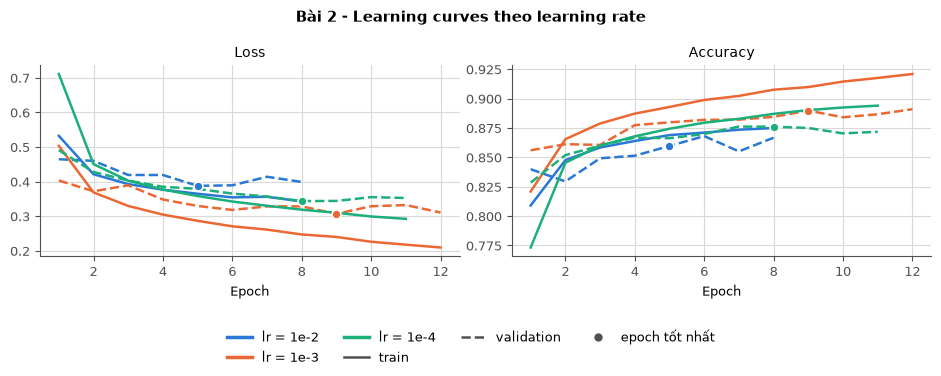


Nhận xét learning curve:
- lr = 1e-2: val_loss tăng ở 2/7 lần chuyển epoch (1e-3: 5/11); epoch tốt nhất 5, val acc 0.8597, thấp hơn 1e-3 0.0301 -> bước cập nhật quá lớn, trọng số nhảy quanh vùng cực tiểu nên dừng ở nghiệm kém hơn.
- lr = 1e-4: train loss sau epoch 1 = 0.7111 (1e-3: 0.5033) -> loss giảm chậm hơn rõ rệt; cần 8 epoch mới đạt val_loss tốt nhất (1e-3: 9 epoch); đường cong mượt, ít dao động.
- lr = 1e-3: epoch tốt nhất 9, val acc 0.8898, test acc 0.8844.
- Kết luận: lr quá lớn -> học nhanh nhưng dao động, khó hội tụ tới điểm tốt; lr quá nhỏ -> ổn định nhưng chậm, tốn nhiều epoch; lr = 1e-3 cho val acc cao nhất, là điểm cân bằng.


In [8]:
show_table("Bài 2: So sánh learning rate", exp_table(
    B2_IDS, B2_LABELS, ["loss_epoch1", "epochs", "best_epoch", "val_loss_tăng", "train_acc", "val_acc", "test_acc", "val_loss"]))
plot_compare(B2_IDS, B2_LABELS, "Bài 2 - Learning curves theo learning rate", "b2.png")


def comment_b2():
    hi, bs, lo = (RESULTS[e] for e in B2_IDS)
    frac = lambda r: n_ups(r) / max(r["epochs_run"] - 1, 1)
    L = []
    t = (f"lr = 1e-2: val_loss tăng ở {n_ups(hi)}/{hi['epochs_run'] - 1} lần chuyển epoch "
         f"(1e-3: {n_ups(bs)}/{bs['epochs_run'] - 1})")
    t += " -> learning curve dao động, giật cục" if frac(hi) > frac(bs) else ""
    t += f"; epoch tốt nhất {hi['best_epoch']}, val acc {hi['val_acc']:.4f}"
    if hi["val_acc"] < bs["val_acc"]:
        t += (f", thấp hơn 1e-3 {bs['val_acc'] - hi['val_acc']:.4f} -> bước cập nhật quá lớn, trọng số nhảy quanh "
              f"vùng cực tiểu nên dừng ở nghiệm kém hơn.")
    else:
        t += " – lần chạy này lr lớn không làm giảm accuracy nhưng quá trình học kém ổn định hơn."
    L.append(t)
    t = f"lr = 1e-4: train loss sau epoch 1 = {lo['history']['loss'][0]:.4f} (1e-3: {bs['history']['loss'][0]:.4f})"
    t += " -> loss giảm chậm hơn rõ rệt" if lo["history"]["loss"][0] > bs["history"]["loss"][0] else ""
    t += f"; cần {lo['best_epoch']} epoch mới đạt val_loss tốt nhất (1e-3: {bs['best_epoch']} epoch)"
    if lo["best_epoch"] == lo["epochs_run"] == MAX_EPOCHS:
        t += f"; đến epoch {MAX_EPOCHS} val_loss vẫn còn giảm -> chưa hội tụ hết"
    t += "; đường cong mượt, ít dao động." if frac(lo) <= frac(bs) else "."
    L.append(t)
    L.append(f"lr = 1e-3: epoch tốt nhất {bs['best_epoch']}, val acc {bs['val_acc']:.4f}, test acc {bs['test_acc']:.4f}.")
    best = max(B2_IDS, key=lambda e: RESULTS[e]["val_acc"])
    L.append("Kết luận: lr quá lớn -> học nhanh nhưng dao động, khó hội tụ tới điểm tốt; lr quá nhỏ -> ổn định nhưng chậm, "
             "tốn nhiều epoch; " + ("lr = 1e-3 cho val acc cao nhất, là điểm cân bằng." if best == "baseline" else
                                     f"lần chạy này {B2_LABELS[best]} cho val acc cao nhất ({RESULTS[best]['val_acc']:.4f})."))
    return L


show_comments("Nhận xét learning curve:", comment_b2())

## Bài 3. Thử batch size: 32, 128, 512
Giữ `lr = 1e-3`; batch 64 của baseline đưa vào làm mốc.

In [9]:
B3_IDS = ["b3_bs_32", "baseline", "b3_bs_128", "b3_bs_512"]
B3_LABELS = {"b3_bs_32": "batch 32", "baseline": "batch 64", "b3_bs_128": "batch 128", "b3_bs_512": "batch 512"}
for bs_ in (32, 128, 512):
    run_experiment(f"b3_bs_{bs_}", B3_LABELS[f"b3_bs_{bs_}"], batch_size=bs_)


=== [b3_bs_32] batch 32 | hidden=(256, 128), lr=0.001, batch=32, dropout=0.0, l2=0 ===
Epoch 1/40


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1563/1563 - 6s - 4ms/step - accuracy: 0.8238 - loss: 0.4899 - val_accuracy: 0.8553 - val_loss: 0.3998
Epoch 2/40
1563/1563 - 5s - 3ms/step - accuracy: 0.8652 - loss: 0.3696 - val_accuracy: 0.8624 - val_loss: 0.3805
Epoch 3/40
1563/1563 - 4s - 3ms/step - accuracy: 0.8784 - loss: 0.3303 - val_accuracy: 0.8754 - val_loss: 0.3388
Epoch 4/40
1563/1563 - 5s - 3ms/step - accuracy: 0.8859 - loss: 0.3057 - val_accuracy: 0.8791 - val_loss: 0.3465
Epoch 5/40
1563/1563 - 5s - 3ms/step - accuracy: 0.8927 - loss: 0.2872 - val_accuracy: 0.8729 - val_loss: 0.3373
Epoch 6/40
1563/1563 - 5s - 3ms/step - accuracy: 0.8965 - loss: 0.2725 - val_accuracy: 0.8794 - val_loss: 0.3256
Epoch 7/40
1563/1563 - 5s - 3ms/step - accuracy: 0.9032 - loss: 0.2582 - val_accuracy: 0.8850 - val_loss: 0.3229
Epoch 8/40
1563/1563 - 5s - 3ms/step - accuracy: 0.9070 - loss: 0.2475 - val_accuracy: 0.8773 - val_loss: 0.3540
Epoch 9/40
1563/1563 - 5s - 3ms/step - accuracy: 0.9101 - loss: 0.2392 - val_accuracy: 0.8875 - val_loss: 0


======== Bài 3: So sánh batch size (lr = 1e-3) ========
          steps/epoch s/epoch epochs best_epoch time_s val_acc test_acc     gap
batch 32        1,563    4.73     12          9   57.4  0.8875   0.8859  0.0311
batch 64          782    2.38     12          9   29.7  0.8898   0.8844  0.0327
batch 128         391    1.27     12          9   16.0  0.8880   0.8838  0.0332
batch 512          98    0.68     17         14   12.6  0.8923   0.8892  0.0357


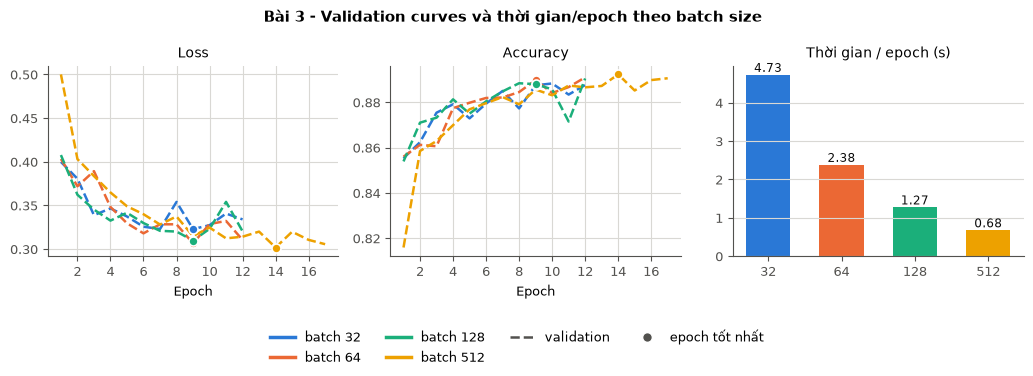


Nhận xét tốc độ và kết quả:
- Tốc độ: số bước cập nhật/epoch 1,563 / 782 / 391 / 98; thời gian/epoch 4.73 / 2.38 / 1.27 / 0.68 s -> batch 512 nhanh hơn batch 32 khoảng 7.0 lần mỗi epoch (mỗi bước xử lý song song nhiều mẫu, tổng số bước ít hơn).
- Epoch tốt nhất: 9 / 9 / 9 / 14; tổng thời gian train: 57 / 30 / 16 / 13 s -> batch lớn cần nhiều epoch hơn vì mỗi epoch ít lần cập nhật trọng số, nên tổng thời gian không giảm tương ứng.
- Kết quả: val acc 0.8875 / 0.8898 / 0.8880 / 0.8923; test acc 0.8859 / 0.8844 / 0.8838 / 0.8892 -> chênh lệch accuracy giữa các batch size nhỏ.
- Kết luận: batch 512 cho val acc cao nhất. Batch nhỏ: mỗi epoch chậm, gradient nhiễu; batch lớn: mỗi epoch nhanh, gradient ổn định nhưng ít lần cập nhật. Khi tăng batch size thường phải tăng learning rate theo.


In [10]:
show_table("Bài 3: So sánh batch size (lr = 1e-3)", exp_table(
    B3_IDS, B3_LABELS, ["steps/epoch", "s/epoch", "epochs", "best_epoch", "time_s", "val_acc", "test_acc", "gap"]))
plot_compare(B3_IDS, B3_LABELS, "Bài 3 - Validation curves và thời gian/epoch theo batch size", "b3.png",
                               show_train=False,
                               bar=("Thời gian / epoch (s)", lambda r: r["sec_per_epoch"], ["32", "64", "128", "512"]))


def comment_b3():
    r32, r64, r128, r512 = (RESULTS[e] for e in B3_IDS)
    rs = (r32, r64, r128, r512)
    L = []
    speedup = r32["sec_per_epoch"] / max(r512["sec_per_epoch"], 1e-9)
    t = ("Tốc độ: số bước cập nhật/epoch " + " / ".join(f"{r['steps_per_epoch']:,}" for r in rs)
         + "; thời gian/epoch " + " / ".join(f"{r['sec_per_epoch']:.2f}" for r in rs) + " s")
    t += (f" -> batch 512 nhanh hơn batch 32 khoảng {speedup:.1f} lần mỗi epoch (mỗi bước xử lý song song nhiều mẫu, "
          f"tổng số bước ít hơn)." if speedup > 1.15 else
          " -> batch lớn gần như không nhanh hơn mỗi epoch (thường gặp khi chạy CPU).")
    L.append(t)
    t = ("Epoch tốt nhất: " + " / ".join(str(r["best_epoch"]) for r in rs)
         + "; tổng thời gian train: " + " / ".join(f"{r['train_time']:.0f}" for r in rs) + " s")
    t += (" -> batch lớn cần nhiều epoch hơn vì mỗi epoch ít lần cập nhật trọng số, nên tổng thời gian không giảm "
          "tương ứng." if r512["best_epoch"] > r32["best_epoch"] else ".")
    L.append(t)
    best = max(B3_IDS, key=lambda e: RESULTS[e]["val_acc"])
    t = ("Kết quả: val acc " + " / ".join(f"{r['val_acc']:.4f}" for r in rs)
         + "; test acc " + " / ".join(f"{r['test_acc']:.4f}" for r in rs))
    if best != "b3_bs_512" and RESULTS[best]["val_acc"] - r512["val_acc"] > 0.002:
        t += (f" -> batch 512 thấp hơn cấu hình tốt nhất {RESULTS[best]['val_acc'] - r512['val_acc']:.4f}: cùng lr nhưng "
              f"ít lần cập nhật, gradient ít nhiễu nên tổng quát hóa kém hơn một chút; batch nhỏ có gradient nhiễu, "
              f"giống regularization nhẹ.")
    else:
        t += " -> chênh lệch accuracy giữa các batch size nhỏ."
    L.append(t)
    L.append(f"Kết luận: {B3_LABELS[best]} cho val acc cao nhất. Batch nhỏ: mỗi epoch chậm, gradient nhiễu; batch lớn: "
             f"mỗi epoch nhanh, gradient ổn định nhưng ít lần cập nhật. Khi tăng batch size thường phải tăng learning "
             f"rate theo.")
    return L


show_comments("Nhận xét tốc độ và kết quả:", comment_b3())

## Bài 4. Thêm `Dropout(0.3)` giữa các Dense layer
`Flatten → Dense(256) → Dropout(0.3) → Dense(128) → Dropout(0.3) → Dense(10)`. Quan sát khoảng cách train/validation accuracy.

In [11]:
B4_IDS = ["baseline", "b4_dropout_0_3"]
B4_LABELS = {"baseline": "Không Dropout", "b4_dropout_0_3": "Dropout(0.3)"}
run_experiment("b4_dropout_0_3", B4_LABELS["b4_dropout_0_3"], dropout=0.3)


=== [b4_dropout_0_3] Dropout(0.3) | hidden=(256, 128), lr=0.001, batch=64, dropout=0.3, l2=0 ===
Epoch 1/40


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 - 4s - 5ms/step - accuracy: 0.7828 - loss: 0.6133 - val_accuracy: 0.8493 - val_loss: 0.4090
Epoch 2/40
782/782 - 2s - 2ms/step - accuracy: 0.8408 - loss: 0.4392 - val_accuracy: 0.8606 - val_loss: 0.3859
Epoch 3/40
782/782 - 2s - 2ms/step - accuracy: 0.8537 - loss: 0.4010 - val_accuracy: 0.8645 - val_loss: 0.3652
Epoch 4/40
782/782 - 2s - 2ms/step - accuracy: 0.8624 - loss: 0.3749 - val_accuracy: 0.8679 - val_loss: 0.3598
Epoch 5/40
782/782 - 2s - 2ms/step - accuracy: 0.8691 - loss: 0.3593 - val_accuracy: 0.8704 - val_loss: 0.3452
Epoch 6/40
782/782 - 2s - 2ms/step - accuracy: 0.8729 - loss: 0.3467 - val_accuracy: 0.8735 - val_loss: 0.3392
Epoch 7/40
782/782 - 2s - 2ms/step - accuracy: 0.8767 - loss: 0.3359 - val_accuracy: 0.8800 - val_loss: 0.3296
Epoch 8/40
782/782 - 2s - 2ms/step - accuracy: 0.8787 - loss: 0.3264 - val_accuracy: 0.8760 - val_loss: 0.3329
Epoch 9/40
782/782 - 2s - 2ms/step - accuracy: 0.8802 - loss: 0.3216 - val_accuracy: 0.8793 - val_loss: 0.3262
Epoch 10/40


{'exp_id': 'b4_dropout_0_3',
 'label': 'Dropout(0.3)',
 'hidden_units': (256, 128),
 'lr': 0.001,
 'batch_size': 64,
 'dropout': 0.3,
 'l2': 0.0,
 'params': 235146,
 'steps_per_epoch': 782,
 'epochs_run': 26,
 'best_epoch': 23,
 'train_time': 43.582952900003875,
 'sec_per_epoch': 1.5944053999846801,
 'best_val_loss_keras': 0.2981838285923004,
 'train_acc': 0.9249,
 'train_loss': 0.19863945245742798,
 'val_acc': 0.8954,
 'val_loss': 0.29815995693206787,
 'test_acc': 0.886,
 'test_loss': 0.32951620221138,
 'gap': 0.02950000000000008,
 'kernel_sq': 5212.880859375,
 'history': {'accuracy': [0.7827600240707397,
   0.8408200144767761,
   0.8536999821662903,
   0.8623800277709961,
   0.8691200017929077,
   0.8729199767112732,
   0.8766599893569946,
   0.8786600232124329,
   0.8802000284194946,
   0.8845199942588806,
   0.8839600086212158,
   0.8876199722290039,
   0.8904399871826172,
   0.891979992389679,
   0.8947200179100037,
   0.8960800170898438,
   0.8975800275802612,
   0.89950001239776


======== Bài 4: Baseline và Dropout(0.3) ========
              best_epoch train_acc_fit train_acc val_acc test_acc     gap
Không Dropout          9        0.9098    0.9225  0.8898   0.8844  0.0327
Dropout(0.3)          23        0.9049    0.9249  0.8954   0.8860  0.0295


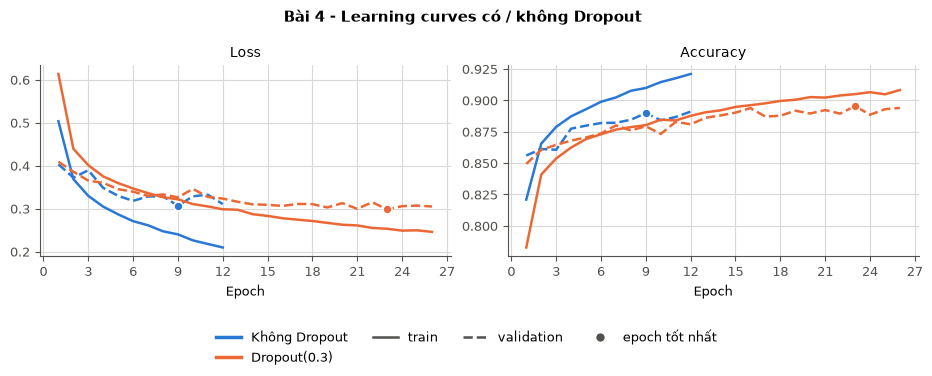


Nhận xét:
- train_acc_fit = accuracy hiển thị lúc fit (Dropout đang bật); train_acc = đo lại trên tập train ở chế độ inference; gap = train_acc - val_acc.
- Gap train - val: 0.0327 -> 0.0295 (giảm 0.0032): Dropout tắt ngẫu nhiên 30% neuron mỗi bước nên mạng không phụ thuộc vào vài neuron cụ thể -> giảm học thuộc dữ liệu train.
- Val acc 0.8898 -> 0.8954 (+0.0056); test acc 0.8844 -> 0.8860 (+0.0016); train acc 0.9225 -> 0.9249.
- Train acc lúc fit chỉ 0.9049, thấp hơn train acc đo lại (0.9249) vì Dropout đang bật -> trên learning curve hai đường train/validation sát nhau hơn baseline.
- Epoch tốt nhất: 9 -> 23 -> Dropout làm mô hình học chậm hơn, cần nhiều epoch hơn.


In [12]:
show_table("Bài 4: Baseline và Dropout(0.3)", exp_table(
    B4_IDS, B4_LABELS, ["best_epoch", "train_acc_fit", "train_acc", "val_acc", "test_acc", "gap"]))
plot_compare(B4_IDS, B4_LABELS, "Bài 4 - Learning curves có / không Dropout", "b4.png")


def comment_b4():
    b, d = RESULTS["baseline"], RESULTS["b4_dropout_0_3"]
    L = ["train_acc_fit = accuracy hiển thị lúc fit (Dropout đang bật); train_acc = đo lại trên tập train ở chế độ "
         "inference; gap = train_acc - val_acc."]
    t = f"Gap train - val: {b['gap']:.4f} -> {d['gap']:.4f}"
    t += (f" (giảm {b['gap'] - d['gap']:.4f}): Dropout tắt ngẫu nhiên 30% neuron mỗi bước nên mạng không phụ thuộc vào "
          f"vài neuron cụ thể -> giảm học thuộc dữ liệu train." if d["gap"] < b["gap"] else
          " -> gap không giảm trong lần chạy này.")
    L.append(t)
    L.append(f"Val acc {b['val_acc']:.4f} -> {d['val_acc']:.4f} ({d['val_acc'] - b['val_acc']:+.4f}); test acc "
             f"{b['test_acc']:.4f} -> {d['test_acc']:.4f} ({d['test_acc'] - b['test_acc']:+.4f}); train acc "
             f"{b['train_acc']:.4f} -> {d['train_acc']:.4f}.")
    fit_acc = d["history"]["accuracy"][d["best_epoch"] - 1]
    if fit_acc < d["train_acc"]:
        t = (f"Train acc lúc fit chỉ {fit_acc:.4f}, thấp hơn train acc đo lại ({d['train_acc']:.4f}) vì Dropout đang bật")
        t += (" -> trên learning curve đường train accuracy nằm dưới đường validation; đây là hiện tượng bình thường "
              "khi dùng Dropout." if fit_acc < d["val_acc"] else
              " -> trên learning curve hai đường train/validation sát nhau hơn baseline.")
        L.append(t)
    L.append(f"Epoch tốt nhất: {b['best_epoch']} -> {d['best_epoch']}"
             + (" -> Dropout làm mô hình học chậm hơn, cần nhiều epoch hơn." if d["best_epoch"] > b["best_epoch"] else "."))
    return L


show_comments("Nhận xét:", comment_b4())

## Bài 5. Thêm L2 regularization
`kernel_regularizer=tf.keras.regularizers.l2(λ)` cho các hidden layer, thử `λ = 1e-4` và `λ = 1e-3`.

In [13]:
L2_VALUES = (1e-4, 1e-3)
fmt_l2 = lambda l: f"{l:.0e}".replace("e-0", "e-")          # 1e-04 -> 1e-4
B5_IDS = ["baseline"] + [f"b5_l2_{fmt_l2(l)}".replace("-", "_") for l in L2_VALUES]
B5_LABELS = {"baseline": "Không L2"}
for l, eid in zip(L2_VALUES, B5_IDS[1:]):
    B5_LABELS[eid] = f"L2 λ = {fmt_l2(l)}"
    run_experiment(eid, B5_LABELS[eid], l2=l)


=== [b5_l2_1e_4] L2 λ = 1e-4 | hidden=(256, 128), lr=0.001, batch=64, dropout=0.0, l2=0.0001 ===
Epoch 1/40


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 - 2s - 3ms/step - accuracy: 0.8204 - loss: 0.5557 - val_accuracy: 0.8478 - val_loss: 0.4747
Epoch 2/40
782/782 - 2s - 2ms/step - accuracy: 0.8644 - loss: 0.4235 - val_accuracy: 0.8644 - val_loss: 0.4256
Epoch 3/40
782/782 - 2s - 2ms/step - accuracy: 0.8754 - loss: 0.3903 - val_accuracy: 0.8651 - val_loss: 0.4371
Epoch 4/40
782/782 - 2s - 2ms/step - accuracy: 0.8830 - loss: 0.3702 - val_accuracy: 0.8763 - val_loss: 0.4088
Epoch 5/40
782/782 - 2s - 2ms/step - accuracy: 0.8893 - loss: 0.3556 - val_accuracy: 0.8814 - val_loss: 0.3812
Epoch 6/40
782/782 - 2s - 2ms/step - accuracy: 0.8924 - loss: 0.3442 - val_accuracy: 0.8824 - val_loss: 0.3733
Epoch 7/40
782/782 - 2s - 2ms/step - accuracy: 0.8961 - loss: 0.3351 - val_accuracy: 0.8720 - val_loss: 0.4123
Epoch 8/40
782/782 - 3s - 3ms/step - accuracy: 0.8977 - loss: 0.3287 - val_accuracy: 0.8729 - val_loss: 0.4145
Epoch 9/40
782/782 - 3s - 4ms/step - accuracy: 0.8996 - loss: 0.3224 - val_accuracy: 0.8847 - val_loss: 0.3688
Epoch 10/40



======== Bài 5: So sánh hệ số L2 ========
            best_epoch train_acc val_acc test_acc     gap val_loss test_loss  sum_w2
Không L2             9    0.9225  0.8898   0.8844  0.0327   0.3065    0.3223  2278.4
L2 λ = 1e-4          9    0.9079  0.8847   0.8759  0.0232   0.3125    0.3364   622.5
L2 λ = 1e-3          9    0.8863  0.8705   0.8643  0.0158   0.3460    0.3662   204.1


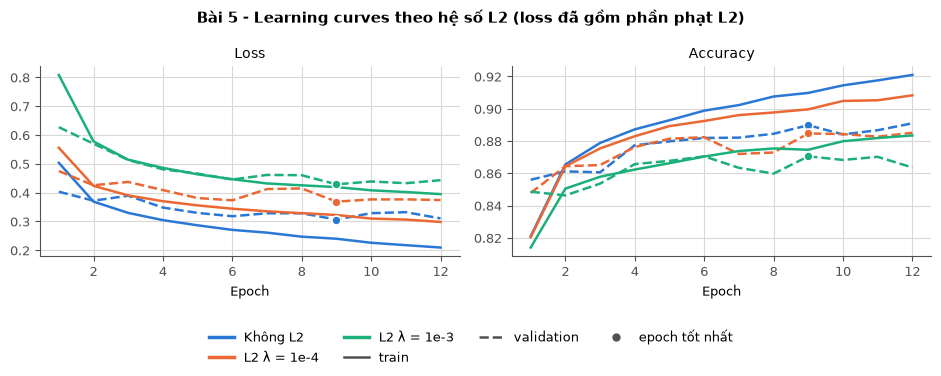


Nhận xét:
- sum_w2 = tổng bình phương trọng số kernel: 2278.4 / 622.5 / 204.1 -> L2 càng mạnh, trọng số càng bị kéo về gần 0, mô hình mượt hơn.
- L2 λ = 1e-4: gap 0.0327 -> 0.0232; val acc 0.8847 (-0.0051); test acc 0.8759 (-0.0085) -> gap thu hẹp, giảm overfitting.
- L2 λ = 1e-3: gap 0.0327 -> 0.0158; val acc 0.8705 (-0.0193); test acc 0.8643 (-0.0201) -> kéo cả train lẫn val acc xuống: bắt đầu underfitting (phạt quá mạnh).
- loss/val_loss trên learning curve của mô hình L2 đã cộng thêm λ·Σw² nên nằm cao hơn baseline; val_loss, test_loss trong bảng là cross-entropy thuần để so sánh công bằng.
- Kết luận: theo validation, Không L2 tốt nhất; λ quá nhỏ gần như không tác dụng, λ quá lớn gây underfitting -> λ phải chọn bằng validation.


In [14]:
show_table("Bài 5: So sánh hệ số L2", exp_table(
    B5_IDS, B5_LABELS, ["best_epoch", "train_acc", "val_acc", "test_acc", "gap", "val_loss", "test_loss", "sum_w2"]))
plot_compare(B5_IDS, B5_LABELS, "Bài 5 - Learning curves theo hệ số L2 (loss đã gồm phần phạt L2)", "b5.png")


def comment_b5():
    b = RESULTS["baseline"]
    L = ["sum_w2 = tổng bình phương trọng số kernel: " + " / ".join(f"{RESULTS[e]['kernel_sq']:.1f}" for e in B5_IDS)
         + " -> L2 càng mạnh, trọng số càng bị kéo về gần 0, mô hình mượt hơn."]
    for e in B5_IDS[1:]:
        r = RESULTS[e]
        t = (f"{B5_LABELS[e]}: gap {b['gap']:.4f} -> {r['gap']:.4f}; val acc {r['val_acc']:.4f} "
             f"({r['val_acc'] - b['val_acc']:+.4f}); test acc {r['test_acc']:.4f} ({r['test_acc'] - b['test_acc']:+.4f})")
        if r["train_acc"] < b["train_acc"] - 0.02 and r["val_acc"] < b["val_acc"]:
            t += " -> kéo cả train lẫn val acc xuống: bắt đầu underfitting (phạt quá mạnh)."
        elif r["gap"] < b["gap"]:
            t += " -> gap thu hẹp, giảm overfitting."
        else:
            t += "."
        L.append(t)
    L.append("loss/val_loss trên learning curve của mô hình L2 đã cộng thêm λ·Σw² nên nằm cao hơn baseline; val_loss, "
             "test_loss trong bảng là cross-entropy thuần để so sánh công bằng.")
    best = max(B5_IDS, key=lambda e: RESULTS[e]["val_acc"])
    L.append(f"Kết luận: theo validation, {B5_LABELS[best]} tốt nhất; λ quá nhỏ gần như không tác dụng, λ quá lớn gây "
             f"underfitting -> λ phải chọn bằng validation.")
    return L


show_comments("Nhận xét:", comment_b5())

## Bài 6. Phân tích lỗi
Dùng mô hình baseline: xem confusion matrix để biết lớp nào hay bị nhầm, sau đó tìm 20 mẫu dự đoán sai với confidence cao nhất và phân tích vì sao chúng khó.


======== Bài 6: Top 5 cặp lớp bị nhầm nhiều nhất trên test (baseline) ========
                       tổng                     A -> B                     B -> A
T-shirt/top <-> Shirt   234  T-shirt/top -> Shirt: 122  Shirt -> T-shirt/top: 112
Pullover <-> Coat       191      Pullover -> Coat: 101       Coat -> Pullover: 90
Pullover <-> Shirt      165      Pullover -> Shirt: 72      Shirt -> Pullover: 93
Coat <-> Shirt          123          Coat -> Shirt: 43          Shirt -> Coat: 80
Dress <-> Coat           76          Dress -> Coat: 14          Coat -> Dress: 62


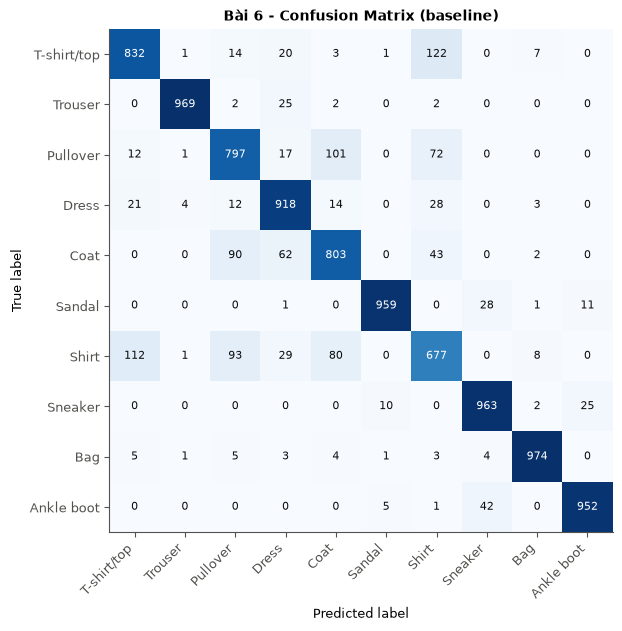


======== Bài 6: 20 mẫu dự đoán sai có confidence cao nhất (baseline) ========
    index_test         true         pred confidence p(true)
1         4394        Dress          Bag     0.9999  0.0000
2         1300          Bag       Sandal     0.9994  0.0000
3          787      Trouser        Dress     0.9993  0.0005
4         5235       Sandal          Bag     0.9991  0.0009
5         9574     Pullover        Shirt     0.9991  0.0004
6         5155        Shirt     Pullover     0.9989  0.0007
7         6565          Bag      Sneaker     0.9989  0.0011
8         3531  T-shirt/top        Dress     0.9980  0.0003
9          324         Coat        Shirt     0.9979  0.0018
10        3866       Sandal   Ankle boot     0.9976  0.0020
11        4693      Sneaker   Ankle boot     0.9965  0.0012
12        2856        Shirt  T-shirt/top     0.9962  0.0036
13        9059        Dress      Trouser     0.9942  0.0029
14        2022      Sneaker   Ankle boot     0.9942  0.0058
15        1111  T-shi

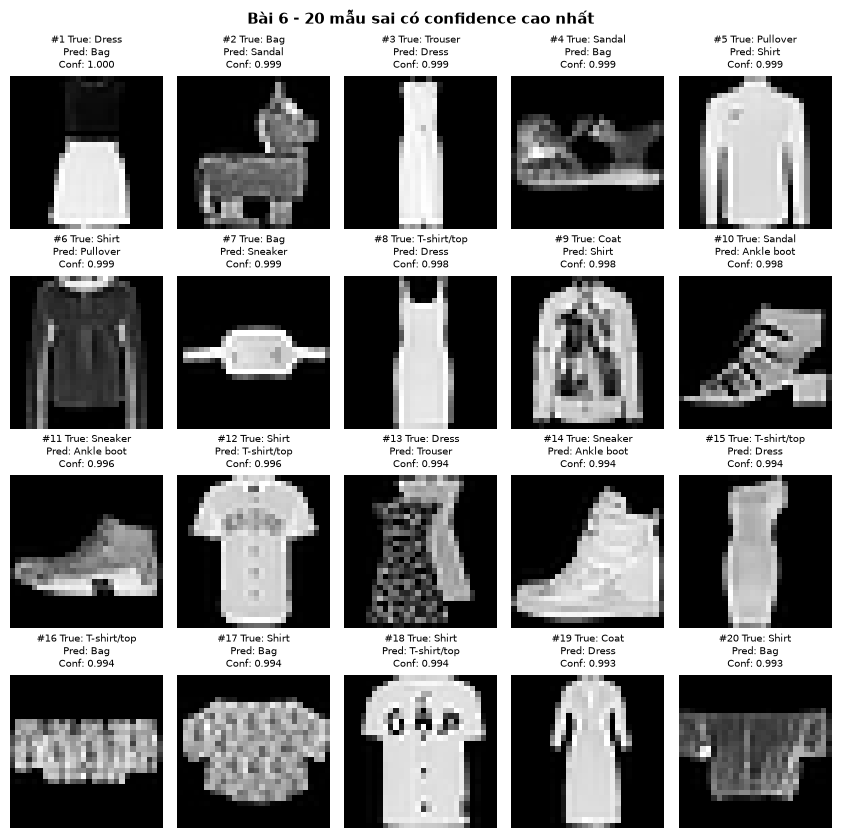


Phân tích:
- Mô hình sai 1,156/10,000 ảnh test. 20 mẫu sai "tự tin" nhất có confidence 0.993 - 1.000, trong khi xác suất gán cho lớp đúng trung bình chỉ 0.0022.
- Trên toàn test, hai cặp bị nhầm nhiều nhất là T-shirt/top <-> Shirt (234 mẫu) và Pullover <-> Coat (191 mẫu); ô ngoài đường chéo của confusion matrix tập trung ở các lớp có hình dạng giống nhau.
- Bag <-> Sandal (2 mẫu): túi xách có hình dạng rất đa dạng, khi thu nhỏ 28x28 một số túi trông giống khối áo hoặc giày.
- Dress <-> Trouser (2 mẫu): váy dáng ống hẹp hoặc jumpsuit dễ trông giống quần dài.
- Pullover <-> Shirt (2 mẫu): đều là áo dài tay, silhouette gần trùng nhau; khác ở cổ áo, cúc, chất liệu – ảnh xám nhỏ không thể hiện rõ.
- Nguyên nhân chung: Flatten biến ảnh thành vector 784 chiều nên MLP mất quan hệ không gian giữa các pixel lân cận, khó học chi tiết cục bộ (cổ áo, cúc, quai giày); ảnh 28x28 xám không có màu và texture; một số ảnh có ranh giới lớp mơ hồ, mắt người cũng khó phân biệt.
- Cả 20 mẫu đều sai với conf

In [15]:
y_prob = RESULTS["baseline"]["y_prob"]
y_pred = np.argmax(y_prob, axis=1)
conf = y_prob.max(axis=1)
wrong_idx = np.where(y_pred != y_test)[0]
TOP20 = wrong_idx[np.argsort(-conf[wrong_idx])][:20]

PAIR_REASONS = {
    frozenset({"Shirt", "T-shirt/top"}): "cùng là áo thân trên, dáng gần giống; khác ở cổ áo, hàng cúc, tay áo – chỉ vài pixel ở 28x28",
    frozenset({"Shirt", "Pullover"}): "đều là áo dài tay, silhouette gần trùng nhau; khác ở cổ áo, cúc, chất liệu – ảnh xám nhỏ không thể hiện rõ",
    frozenset({"Coat", "Pullover"}): "đều dài tay, dày; khác biệt (khóa kéo, cúc, vạt áo mở) là các đường rất mảnh",
    frozenset({"Coat", "Shirt"}): "áo khoác mỏng và sơ mi dài tay đều có đường cúc/khóa ở giữa nên hình dạng gần giống hệt",
    frozenset({"Pullover", "T-shirt/top"}): "áo len tay lửng hoặc áo phông dài tay làm mờ đặc trưng chính là độ dài tay áo",
    frozenset({"Dress", "T-shirt/top"}): "váy suông ngắn và áo phông dài cùng dạng hình chữ nhật thẳng",
    frozenset({"Dress", "Shirt"}): "váy sơ mi và áo sơ mi dài có cùng cổ áo, hàng cúc, dáng thẳng",
    frozenset({"Coat", "Dress"}): "áo khoác dáng dài trông giống váy liền thân",
    frozenset({"Dress", "Pullover"}): "váy len dài tay và áo len dáng dài có hình dạng tương tự",
    frozenset({"Dress", "Trouser"}): "váy dáng ống hẹp hoặc jumpsuit dễ trông giống quần dài",
    frozenset({"Sandal", "Sneaker"}): "sandal đế dày/kín mũi và giày thể thao thấp cổ có hình dạng tương tự; khác ở quai mảnh và khoảng hở",
    frozenset({"Ankle boot", "Sneaker"}): "giày thể thao cổ cao trông giống bốt cổ ngắn",
    frozenset({"Ankle boot", "Sandal"}): "sandal cổ cao, quai bản lớn tạo khối giống bốt",
}


def pair_reason(a, b):
    key = frozenset({a, b})
    if key in PAIR_REASONS:
        return PAIR_REASONS[key]
    if "Bag" in key:
        return "túi xách có hình dạng rất đa dạng, khi thu nhỏ 28x28 một số túi trông giống khối áo hoặc giày"
    return "cặp ít khi nhầm; thường do ảnh có hình dạng bất thường (bị cắt, chụp nghiêng, kiểu dáng lạ) hoặc nhãn bị gán nhầm"


# --- Confusion matrix và các cặp lớp bị nhầm nhiều nhất trên toàn test (cộng cả 2 chiều) ---
cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))
pairs = sorted(((cm[i, j] + cm[j, i], i, j) for i in range(10) for j in range(i + 1, 10)), reverse=True)
show_table("Bài 6: Top 5 cặp lớp bị nhầm nhiều nhất trên test (baseline)", pd.DataFrame([{
    "tổng": int(tot),
    "A -> B": f"{class_names[i]} -> {class_names[j]}: {cm[i, j]}",
    "B -> A": f"{class_names[j]} -> {class_names[i]}: {cm[j, i]}",
} for tot, i, j in pairs[:5]], index=[f"{class_names[i]} <-> {class_names[j]}" for _, i, j in pairs[:5]]))

fig, ax = plt.subplots(figsize=(7.2, 6.4))
ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
ax.set_xticks(range(10)); ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title("Bài 6 - Confusion Matrix (baseline)", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "b6_confusion_matrix.png"), bbox_inches="tight")
plt.show()
plt.close(fig)

# --- 20 mẫu sai có confidence cao nhất ---
top20_df = pd.DataFrame([{
    "index_test": int(i), "true": class_names[y_test[i]], "pred": class_names[y_pred[i]],
    "confidence": f"{conf[i]:.4f}", "p(true)": f"{y_prob[i, y_test[i]]:.4f}",
} for i in TOP20], index=range(1, len(TOP20) + 1))
show_table("Bài 6: 20 mẫu dự đoán sai có confidence cao nhất (baseline)", top20_df)

pc = Counter(" <-> ".join(sorted((class_names[y_test[i]], class_names[y_pred[i]]))) for i in TOP20)
show_table("Các cặp lớp trong 20 mẫu sai", pd.DataFrame({"số mẫu": pc}).sort_values("số mẫu", ascending=False))

fig, axes = plt.subplots(4, 5, figsize=(8.5, 8.6))
for ax in axes.ravel():
    ax.axis("off")
for k, (ax, i) in enumerate(zip(axes.ravel(), TOP20), start=1):
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(f"#{k} True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]}\nConf: {conf[i]:.3f}", fontsize=7.5)
fig.suptitle("Bài 6 - 20 mẫu sai có confidence cao nhất", fontsize=11, fontweight="bold")
fig.tight_layout()
path = os.path.join(FIG_DIR, "b6_top20.png")
fig.savefig(path, bbox_inches="tight")
plt.show()
plt.close(fig)


def comment_b6():
    p_true = y_prob[TOP20, y_test[TOP20]]
    tc = conf[TOP20]
    L = [f"Mô hình sai {len(wrong_idx):,}/{len(y_test):,} ảnh test. 20 mẫu sai \"tự tin\" nhất có confidence "
         f"{tc.min():.3f} - {tc.max():.3f}, trong khi xác suất gán cho lớp đúng trung bình chỉ {p_true.mean():.4f}."]
    (t1, a1, b1), (t2, a2, b2) = pairs[0], pairs[1]
    L.append(f"Trên toàn test, hai cặp bị nhầm nhiều nhất là {class_names[a1]} <-> {class_names[b1]} ({t1} mẫu) và "
             f"{class_names[a2]} <-> {class_names[b2]} ({t2} mẫu); ô ngoài đường chéo của confusion matrix tập trung ở "
             f"các lớp có hình dạng giống nhau.")
    for pair, v in pc.most_common(3):
        a, b = pair.split(" <-> ")
        L.append(f"{pair} ({v} mẫu): {pair_reason(a, b)}.")
    L.append("Nguyên nhân chung: Flatten biến ảnh thành vector 784 chiều nên MLP mất quan hệ không gian giữa các pixel "
             "lân cận, khó học chi tiết cục bộ (cổ áo, cúc, quai giày); ảnh 28x28 xám không có màu và texture; một số "
             "ảnh có ranh giới lớp mơ hồ, mắt người cũng khó phân biệt.")
    if tc.min() >= 0.9:
        L.append("Cả 20 mẫu đều sai với confidence >= 0.9 -> mô hình tự tin thái quá (overconfident), xác suất softmax "
                 "không phản ánh đúng độ chắc chắn.")
    L.append("Hướng cải thiện: dùng CNN để khai thác cấu trúc không gian, thêm data augmentation và regularization; kiểm "
             "tra lại nhãn của các mẫu sai \"tự tin\".")
    return L


show_comments("Phân tích:", comment_b6())